<a href="https://colab.research.google.com/github/praveena161/CSA4710-DL/blob/main/DL.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
pip install numpy pandas matplotlib scipy scikit-learn tensorflow

1st

Addition: [5 7 9]
Subtraction: [-3 -3 -3]
Multiplication: [ 4 10 18]
Dot Product: 32
Matrix:
 [[1 2]
 [3 4]]
Transpose:
 [[1 3]
 [2 4]]
Inverse:
 [[-2.   1. ]
 [ 1.5 -0.5]]


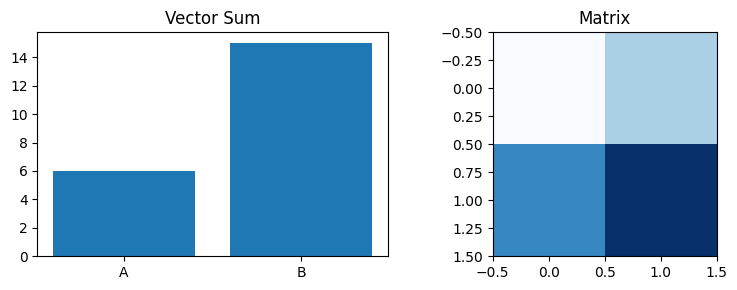

In [9]:
import numpy as np
import matplotlib.pyplot as plt

A = np.array([1, 2, 3])
B = np.array([4, 5, 6])

print("Addition:", A+B)
print("Subtraction:", A-B)
print("Multiplication:", A*B)
print("Dot Product:", np.dot(A,B))

M = np.array([[1, 2], [3, 4]])
print("Matrix:\n", M)
print("Transpose:\n", M.T)
print("Inverse:\n", np.linalg.inv(M))

fig, ax = plt.subplots(1, 2, figsize=(8, 3))
ax[0].bar(["A", "B"], [sum(A), sum(B)])
ax[0].set_title("Vector Sum")
ax[1].imshow(M, cmap="Blues")
ax[1].set_title("Matrix")
plt.tight_layout()
plt.show()

2nd

Covariance:
           X         Y
X  6.666667  6.666667
Y  6.666667  6.666667
Eigenvalues: [13.33333333  0.        ]
Eigenvectors:
 [[ 0.70710678 -0.70710678]
 [ 0.70710678  0.70710678]]


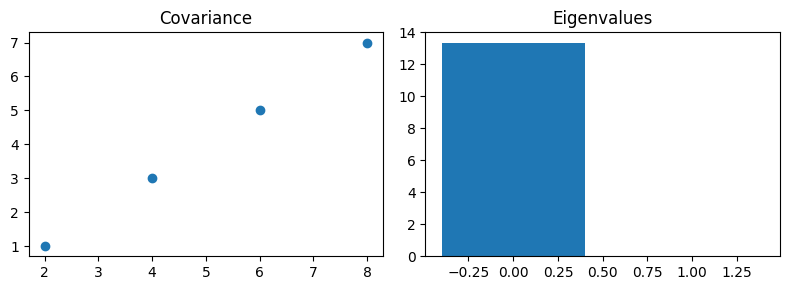

In [10]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

df = pd.DataFrame({"X":[2,4,6,8], "Y":[1,3,5,7]})
C = df.cov()
values, vectors = np.linalg.eig(C)

print("Covariance:\n", C)
print("Eigenvalues:", values)
print("Eigenvectors:\n", vectors)

fig, ax = plt.subplots(1, 2, figsize=(8, 3))
ax[0].scatter(df.X, df.Y)
ax[0].set_title("Covariance")
ax[1].bar(range(2), values)
ax[1].set_title("Eigenvalues")
plt.tight_layout()
plt.show()

3rd

P(B): 0.24000000000000005
P(A|B): 0.6666666666666666


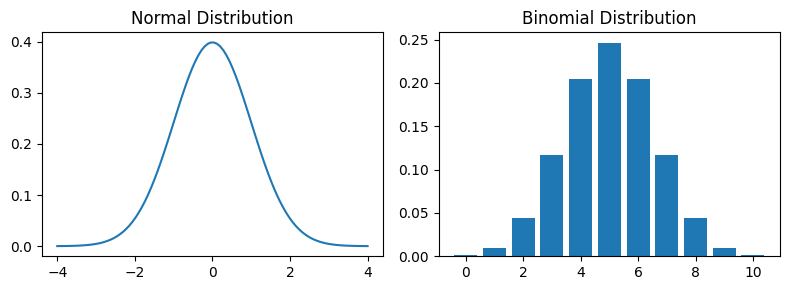

In [11]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm, binom

x = np.linspace(-4, 4, 100)
y = norm.pdf(x)

n, p = 10, 0.5
a = np.arange(n+1)
b = binom.pmf(a, n, p)

PA, PBA, PBNA = 0.2, 0.8, 0.1
PB = PBA*PA + PBNA*(1-PA)
PAB = PBA*PA/PB

print("P(B):", PB)
print("P(A|B):", PAB)

fig, ax = plt.subplots(1, 2, figsize=(8, 3))
ax[0].plot(x, y)
ax[0].set_title("Normal Distribution")
ax[1].bar(a, b)
ax[1].set_title("Binomial Distribution")
plt.tight_layout()
plt.show()

4th

Entropy: 0.9709505944546688
Cross Entropy: 1.0
KL Divergence: 0.029049405545331346


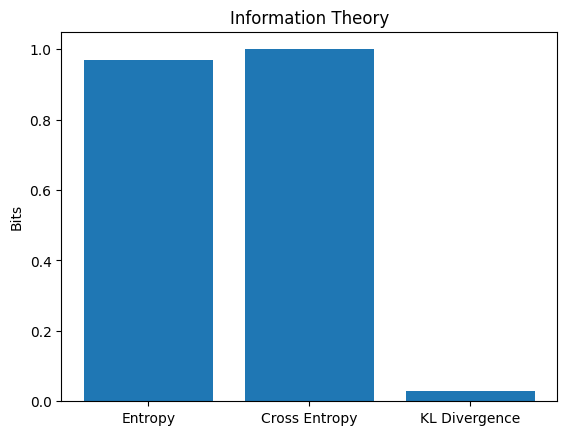

In [12]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import entropy

P = np.array([0.4, 0.6])
Q = np.array([0.5, 0.5])

H = entropy(P, base=2)
CE = -np.sum(P*np.log2(Q))
KL = entropy(P, Q, base=2)

print("Entropy:", H)
print("Cross Entropy:", CE)
print("KL Divergence:", KL)

plt.bar(["Entropy", "Cross Entropy", "KL Divergence"], [H, CE, KL])
plt.ylabel("Bits")
plt.title("Information Theory")
plt.show()

5th

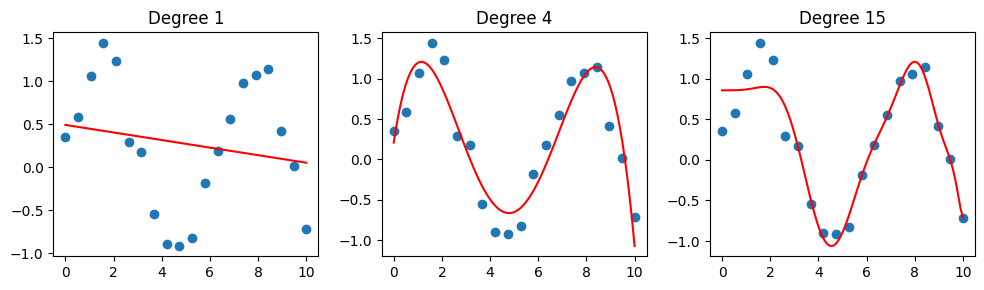

In [13]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression

np.random.seed(0)
X = np.linspace(0, 10, 20).reshape(-1, 1)
y = np.sin(X).ravel() + np.random.normal(0, 0.2, 20)
X1 = np.linspace(0, 10, 100).reshape(-1, 1)

fig, ax = plt.subplots(1, 3, figsize=(10, 3))

for i, degree in enumerate([1, 4, 15]):
    model = make_pipeline(PolynomialFeatures(degree), LinearRegression())
    model.fit(X, y)
    ax[i].scatter(X, y)
    ax[i].plot(X1, model.predict(X1), color="red")
    ax[i].set_title("Degree " + str(degree))

plt.tight_layout()
plt.show()

6th

GD Final Loss: 6.1299821634643125e-06
SGD Final Loss: 0.0016883205629208847
Momentum Final Loss: 0.007759073229505936
Adam Final Loss: 0.04218129485518873


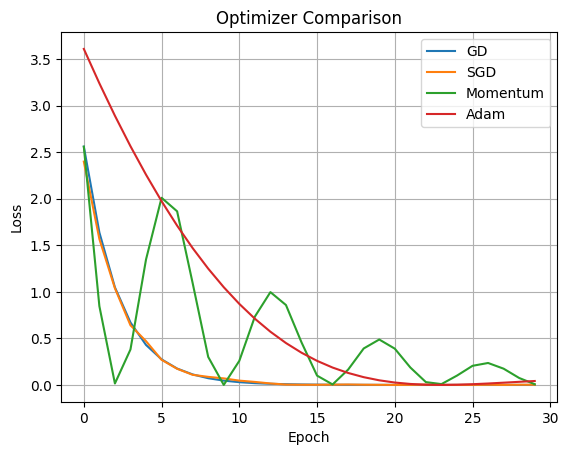

In [14]:
import numpy as np
import matplotlib.pyplot as plt
x = 2.0
lr = 0.1
epochs = 30
methods = ["GD", "SGD", "Momentum", "Adam"]
losses = {}
for method in methods:
    w, v, m, s = 0.0, 0.0, 0.0, 0.0
    L = []
    for t in range(1, epochs+1):
        g = 2*(w-x)
        if method == "GD":
            w -= lr*g
        elif method == "SGD":
            w -= lr*(g + np.random.normal(0, 0.2))
        elif method == "Momentum":
            v = 0.9*v + lr*g
            w -= v
        else:
            m = 0.9*m + 0.1*g
            s = 0.999*s + 0.001*g*g
            w -= lr*(m/(1-0.9**t))/(np.sqrt(s/(1-0.999**t))+1e-8)
        L.append((w-x)**2)
    losses[method] = L
    print(method, "Final Loss:", L[-1])
for method in methods:
    plt.plot(losses[method], label=method)
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Optimizer Comparison")
plt.legend()
plt.grid()
plt.show()

7th

Input:
 [[0 0]
 [0 1]
 [1 0]
 [1 1]]
Output: [0 0 0 1]


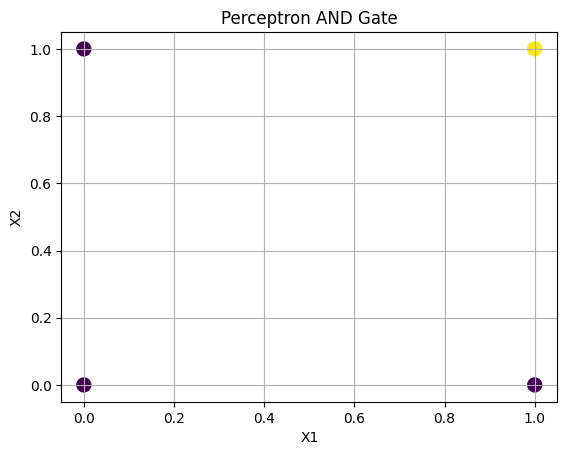

In [15]:
import numpy as np
import matplotlib.pyplot as plt

X = np.array([[0,0],[0,1],[1,0],[1,1]])
w = np.array([1,1])
b = -1.5

z = np.dot(X,w) + b
y = (z >= 0).astype(int)

print("Input:\n", X)
print("Output:", y)

plt.scatter(X[:,0], X[:,1], c=y, s=100)
plt.xlabel("X1")
plt.ylabel("X2")
plt.title("Perceptron AND Gate")
plt.grid()
plt.show()

8th

Predictions:
 [[0.041]
 [0.976]
 [0.976]
 [0.01 ]]


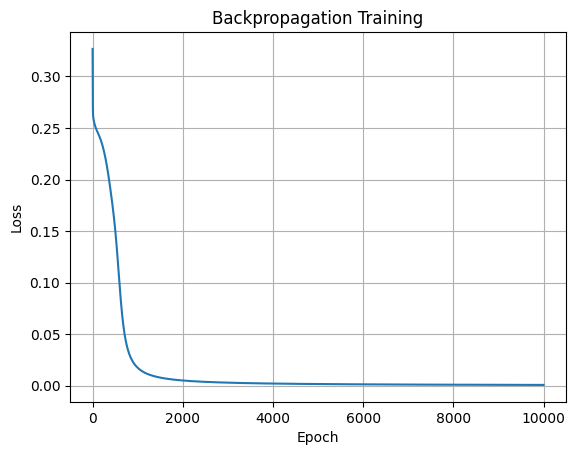

In [16]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(0)
X = np.array([[0,0],[0,1],[1,0],[1,1]])
Y = np.array([[0],[1],[1],[0]])

sigmoid = lambda x: 1/(1+np.exp(-x))

W1 = np.random.randn(2,4)
W2 = np.random.randn(4,1)
lr = 0.5
losses = []

for i in range(10000):
    H = sigmoid(X @ W1)
    O = sigmoid(H @ W2)
    loss = np.mean((Y-O)**2)
    losses.append(loss)

    dO = (O-Y)*O*(1-O)
    dW2 = H.T @ dO
    dH = (dO @ W2.T)*H*(1-H)
    dW1 = X.T @ dH

    W2 -= lr*dW2
    W1 -= lr*dW1

print("Predictions:\n", np.round(O, 3))

plt.plot(losses)
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Backpropagation Training")
plt.grid()
plt.show()

9th

Predictions:
 [[0.041]
 [0.976]
 [0.976]
 [0.01 ]]


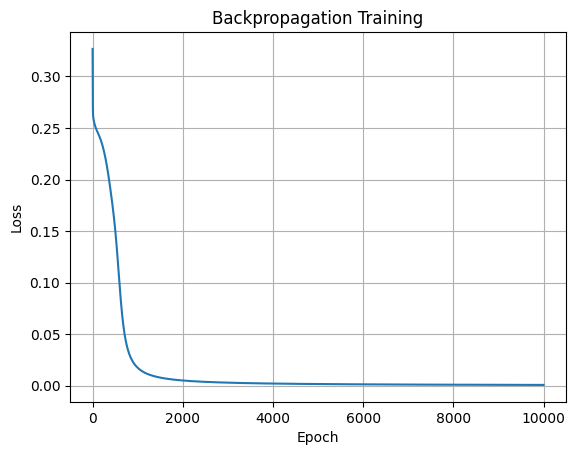

In [17]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(0)
X = np.array([[0,0],[0,1],[1,0],[1,1]])
Y = np.array([[0],[1],[1],[0]])

sigmoid = lambda x: 1/(1+np.exp(-x))

W1 = np.random.randn(2,4)
W2 = np.random.randn(4,1)
lr = 0.5
losses = []

for i in range(10000):
    H = sigmoid(X @ W1)
    O = sigmoid(H @ W2)
    loss = np.mean((Y-O)**2)
    losses.append(loss)

    dO = (O-Y)*O*(1-O)
    dW2 = H.T @ dO
    dH = (dO @ W2.T)*H*(1-H)
    dW1 = X.T @ dH

    W2 -= lr*dW2
    W1 -= lr*dW1

print("Predictions:\n", np.round(O, 3))

plt.plot(losses)
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Backpropagation Training")
plt.grid()
plt.show()

10th

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


L2 Best Validation Accuracy: 0.9678333401679993
Dropout Best Validation Accuracy: 0.9754166603088379
Early Stopping Best Validation Accuracy: 0.9704166650772095


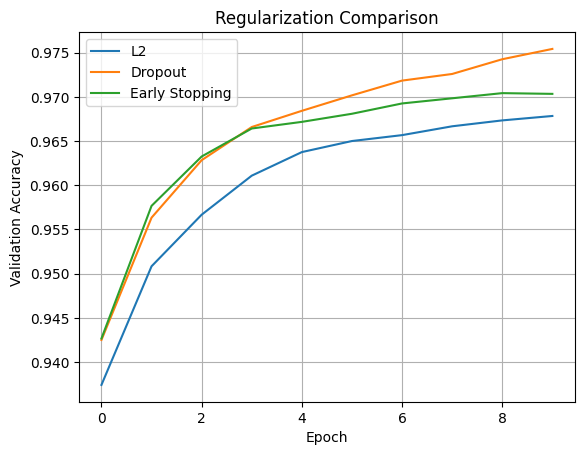

In [18]:
import tensorflow as tf
import matplotlib.pyplot as plt
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.regularizers import l2
from tensorflow.keras.callbacks import EarlyStopping

(X, y), _ = tf.keras.datasets.mnist.load_data()
X = X.reshape(-1, 784)/255.0

def create_model(reg=None, drop=0):
    model = Sequential([
        Dense(128, activation="relu", input_shape=(784,), kernel_regularizer=reg),
        Dropout(drop),
        Dense(10, activation="softmax")
    ])
    model.compile(optimizer="adam",
                  loss="sparse_categorical_crossentropy",
                  metrics=["accuracy"])
    return model

models = {
    "L2": create_model(l2(0.001)),
    "Dropout": create_model(drop=0.3),
    "Early Stopping": create_model()
}

histories = {}

for name, model in models.items():
    callback = [EarlyStopping(patience=2, restore_best_weights=True)] if name == "Early Stopping" else []
    histories[name] = model.fit(
        X, y, epochs=10, batch_size=128,
        validation_split=0.2, callbacks=callback, verbose=0
    )

    print(name, "Best Validation Accuracy:",
          max(histories[name].history["val_accuracy"]))

for name, history in histories.items():
    plt.plot(history.history["val_accuracy"], label=name)

plt.xlabel("Epoch")
plt.ylabel("Validation Accuracy")
plt.title("Regularization Comparison")
plt.legend()
plt.grid()
plt.show()